# 🌧️ වැසි: Sri Lanka Rainfall Ensemble Lab
### Predicting tomorrow's rainfall in Colombo, Kandy and Galle with Bagging, Boosting, Stacking and an RF + ARIMA hybrid

**Module:** Machine Learning (Semester 7), University of Moratuwa · **Hands-on project:** Ensemble Learning Dashboard · **Author:** Sineth

---

## 🤖 GenAI Usage Declaration
As required by the module's Generative AI policy, I explicitly declare that:

- **Claude (Anthropic)** was used as a coding assistant to write and scaffold the code in this notebook (data download, cleaning, feature engineering, model training, evaluation and SHAP analysis), the Streamlit dashboard code and UI, and the README.
- **Gemini (Google)** was used to brainstorm the overall project plan.
- All AI-assisted code was **executed, checked and reviewed by me**. The dataset is **real** (downloaded from the Open-Meteo API) and was **not** generated by AI. Every number in this notebook comes from actually running the cells.

| Part | Written by |
|---|---|
| Project idea, dataset choice (Sri Lankan rainfall), checking every result, interpretation decisions | Me (Sineth) |
| `scripts/fetch_data.py`, all code cells in this notebook, `app.py` dashboard code and UI | **Generated with Claude (Anthropic)**, then run and reviewed by me |
| Project plan brainstorming | Gemini (Google) |

## 0. Problem statement (Sri Lankan context)
Sri Lanka's wet zone is driven by two monsoons, the **South-West (Yala, May–Sep)** and the **North-East (Maha, Dec–Feb)**, plus stormy **inter-monsoon** periods (Mar–Apr, Oct–Nov). A single heavy-rain day floods Colombo's suburbs, raises landslide risk around Kandy and stops fishing boats in Galle.

**Goal:** predict `rain_tomorrow_mm`, the next-day rainfall (mm), for each city using today's weather and recent history, and compare **Bagging, Boosting, Stacking and Hybrid** ensembles, explaining **why** they perform differently.

## 1. Data source and reproducibility

| Item | Value |
|---|---|
| Source | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) |
| Underlying data | **ECMWF ERA5 / ERA5-Land reanalysis** (Copernicus Climate Change Service) |
| Cities | Colombo (6.9271, 79.8612), Kandy (7.2906, 80.6337), Galle (6.0535, 80.2210) |
| Period | 2015-01-01 to 2025-12-31, daily |
| Re-download | `python scripts/fetch_data.py` (no API key) |

**Exact API URL (Colombo; Kandy and Galle only change `latitude`/`longitude`):**
```
https://archive-api.open-meteo.com/v1/archive?latitude=6.9271&longitude=79.8612&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration&timezone=Asia%2FColombo
```

**What is ERA5 reanalysis?** ECMWF combines millions of **real observations** (weather stations, radiosondes, aircraft, ships, buoys, satellites) with a physics-based weather model through *data assimilation*, producing a consistent, gap-free record on a ~9–31 km grid. It is observation-based and fully reproducible, **not synthetic**. Limitation: it is a grid-cell average, so it smooths extreme cloudbursts and over-counts light-drizzle days compared with a single rain gauge.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data/sl_weather_2015_2025.csv")
MODELS_DIR = Path("models"); MODELS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

df_raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print("Shape:", df_raw.shape)
print("Date range:", df_raw["date"].min().date(), "to", df_raw["date"].max().date())
print("Rows per city:", df_raw["city"].value_counts().to_dict())
df_raw.head()

Shape: (12054, 22)
Date range: 2015-01-01 to 2025-12-31
Rows per city: {'Colombo': 4018, 'Kandy': 4018, 'Galle': 4018}


,date,city,climate_zone,latitude,longitude,elevation_m,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,...,precipitation_hours,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration
0,2015-01-01,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,28.4,23.2,25.8,31.0,...,7.0,88,23.6,1009.8,39,11.4,27.4,210,18.30,3.51
1,2015-01-02,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,28.8,22.9,25.5,29.9,...,0.0,82,22.1,1011.8,28,9.6,22.0,282,19.63,3.95
2,2015-01-03,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.9,20.9,25.6,30.2,...,0.0,81,21.9,1012.3,58,9.9,20.2,300,22.94,4.59
3,2015-01-04,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.8,23.2,26.1,30.9,...,0.0,82,22.6,1011.8,37,8.8,20.9,331,18.36,3.78
4,2015-01-05,Colombo,Wet zone - west coast,6.924429,79.90725,9.0,29.6,23.0,26.4,31.6,...,2.0,83,23.1,1011.0,32,7.9,19.4,6,19.99,4.06


In [2]:
# Data types and missing values
info = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing": df_raw.isna().sum(), "n_unique": df_raw.nunique()})
info

,dtype,missing,n_unique
date,datetime64[ns],0,4018
city,object,0,3
climate_zone,object,0,3
latitude,float64,0,3
longitude,float64,0,3
elevation_m,float64,0,3
temperature_2m_max,float64,0,134
temperature_2m_min,float64,0,126
temperature_2m_mean,float64,0,96
apparent_temperature_mean,float64,0,143


## 2. Data cleaning
Every decision below is documented with the reason. Principle: **remove only what is redundant or physically impossible; keep real extremes**, because extreme rain days are exactly the floods we care about.

In [3]:
df = df_raw.sort_values(["city", "date"]).reset_index(drop=True).copy()
report = {}

# 2.1 Duplicates: one row per (city, date) is expected
report["duplicate (city, date) rows"] = int(df.duplicated(["city", "date"]).sum())

# 2.2 Continuity: every city must have every calendar day (needed for lag features and ARIMA)
full_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
report["missing calendar days"] = int(sum(len(full_days.difference(g["date"])) for _, g in df.groupby("city")))

# 2.3 Redundant column: in tropical Sri Lanka there is no snow, so rain_sum should equal precipitation_sum
report["rows where rain_sum != precipitation_sum"] = int((~np.isclose(df["rain_sum"], df["precipitation_sum"])).sum())

# 2.4 Physical sanity checks (impossible values would indicate corruption)
checks = {
    "precipitation < 0": (df["precipitation_sum"] < 0),
    "Tmin > Tmax": (df["temperature_2m_min"] > df["temperature_2m_max"]),
    "humidity outside 0-100 %": ~df["relative_humidity_2m_mean"].between(0, 100),
    "cloud cover outside 0-100 %": ~df["cloud_cover_mean"].between(0, 100),
    "MSL pressure outside 950-1050 hPa": ~df["pressure_msl_mean"].between(950, 1050),
    "precipitation_hours outside 0-24": ~df["precipitation_hours"].between(0, 24),
    "dew point > air temperature + 0.5": (df["dew_point_2m_mean"] > df["temperature_2m_mean"] + 0.5),
}
for name, mask in checks.items():
    report[name] = int(mask.sum())

pd.Series(report, name="count").to_frame()

,count
"duplicate (city, date) rows",0
missing calendar days,0
rows where rain_sum != precipitation_sum,0
precipitation < 0,0
Tmin > Tmax,0
humidity outside 0-100 %,0
cloud cover outside 0-100 %,0
MSL pressure outside 950-1050 hPa,0
precipitation_hours outside 0-24,0
dew point > air temperature + 0.5,0


In [4]:
# Apply the cleaning decisions
df = df.drop(columns=["rain_sum",            # identical to precipitation_sum (no snow in Sri Lanka)
                      "latitude", "longitude"])  # constant per city, already captured by `city`
df = df.rename(columns={"precipitation_sum": "rain_mm"})

# Extreme rainfall: inspect, but DO NOT delete. These are real monsoon / cyclone events.
top_days = df.nlargest(8, "rain_mm")[["date", "city", "rain_mm", "precipitation_hours", "pressure_msl_mean"]]
print("Wettest days in the record (kept, they are real events):")
top_days

Wettest days in the record (kept, they are real events):


,date,city,rain_mm,precipitation_hours,pressure_msl_mean
500,2016-05-15,Colombo,231.4,24.0,1007.0
3984,2025-11-28,Colombo,217.5,23.0,1007.6
6161,2020-11-13,Galle,200.0,20.0,1009.4
8536,2016-05-15,Kandy,172.5,24.0,1008.8
12019,2025-11-27,Kandy,164.9,24.0,1006.7
4315,2015-10-25,Galle,160.1,24.0,1010.8
5771,2019-10-20,Galle,149.4,24.0,1010.2
12020,2025-11-28,Kandy,138.6,24.0,1006.7


**Cleaning decisions and reasons**

| Decision | Reason |
|---|---|
| Keep all 12,054 rows | No duplicates, no missing days, no missing values, no physically impossible values (table above). |
| Drop `rain_sum` | It is identical to `precipitation_sum`. Sri Lanka has no snowfall, so keeping both would just duplicate information. |
| Drop `latitude`, `longitude` | Constant within each city, so they add nothing beyond the `city` column. |
| **Keep** extreme rainfall days (up to 231 mm) | They are real events (monsoon bursts, deep depressions). Deleting them would teach the model that floods never happen. Instead we handle the skew with a **log1p transform** of the target during modeling. |
| Rename `precipitation_sum` to `rain_mm` | Readability. |

**ERA5 caveat:** reanalysis spreads rain over a ~9–31 km grid cell, so it records small amounts of rain (drizzle) on many days that a single gauge would call dry. That is why only 16–37 % of days are below 1 mm. We keep this in mind when interpreting "rain / no-rain" results.

## 3. Feature engineering (Sri Lankan domain knowledge)
All features use information available **by the end of day *t*** to predict rain on day *t + 1*. Lags and rolling windows are computed **per city**, so Colombo's history never leaks into Kandy's rows by accident (the cross-city features below are deliberate and use the same day only).

| Group | Features | Why it should help |
|---|---|---|
| Persistence | `rain_lag1..3`, `rain_roll3/7/14/30` (mean), `wet_streak`, `dry_streak` | Monsoon spells last for days, so recent rain is the strongest single signal. |
| Atmosphere today | humidity, dew point, dew-point depression, cloud cover, radiation, ET0, pressure | Moist, cloudy, low-pressure air is primed for convection. |
| Tendencies | `pressure_change_1d`, `humidity_change_1d`, `temp_range` | Falling pressure signals an approaching low / depression. |
| Wind | `wind_u`, `wind_v` (from speed + direction), gusts | South-westerly flow brings Yala rain to the west and south coasts; north-easterly brings Maha rain. |
| Season | `monsoon_season` (SW, NE, First / Second inter-monsoon), `doy_sin`, `doy_cos`, `month` | Sri Lanka's rain is strongly seasonal. |
| Spatial | `rain_today_colombo/kandy/galle` | Weather systems move across the island; rain in one city today can foreshadow another tomorrow. |
| Location | `city` (one-hot), `elevation_m` | Kandy sits at ~500 m in the central hills, with a different rain regime from the coast. |

In [5]:
def monsoon_season(month):
    if month in (5, 6, 7, 8, 9):
        return "SW monsoon (Yala)"
    if month in (12, 1, 2):
        return "NE monsoon (Maha)"
    if month in (3, 4):
        return "First inter-monsoon"
    return "Second inter-monsoon"   # Oct, Nov


def streak(is_true):
    # length of the current run of True values, reset on False
    run = is_true.astype(int)
    return run.groupby((run != run.shift()).cumsum()).cumsum() * run


def build_features(d):
    d = d.sort_values(["city", "date"]).copy()
    g = d.groupby("city", group_keys=False)

    # Persistence
    for k in (1, 2, 3):
        d[f"rain_lag{k}"] = g["rain_mm"].shift(k)
    for w in (3, 7, 14, 30):
        d[f"rain_roll{w}"] = g["rain_mm"].transform(lambda s: s.rolling(w, min_periods=w).mean())
    d["wet_streak"] = g["rain_mm"].transform(lambda s: streak(s >= 1))
    d["dry_streak"] = g["rain_mm"].transform(lambda s: streak(s < 1))
    d["precip_hours_lag1"] = g["precipitation_hours"].shift(1)

    # Atmosphere and tendencies
    d["temp_range"] = d["temperature_2m_max"] - d["temperature_2m_min"]
    d["dewpoint_depression"] = d["temperature_2m_mean"] - d["dew_point_2m_mean"]
    d["pressure_change_1d"] = g["pressure_msl_mean"].diff(1)
    d["humidity_change_1d"] = g["relative_humidity_2m_mean"].diff(1)

    # Wind vector (meteorological direction = where the wind comes FROM)
    rad = np.deg2rad(d["wind_direction_10m_dominant"])
    d["wind_u"] = -d["wind_speed_10m_max"] * np.sin(rad)
    d["wind_v"] = -d["wind_speed_10m_max"] * np.cos(rad)

    # Season
    d["month"] = d["date"].dt.month
    doy = d["date"].dt.dayofyear
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    d["monsoon_season"] = d["month"].map(monsoon_season)

    # Spatial: every city's rain today, joined on date
    wide = d.pivot(index="date", columns="city", values="rain_mm")
    wide.columns = [f"rain_today_{c.lower()}" for c in wide.columns]
    d = d.merge(wide, left_on="date", right_index=True, how="left")

    # Targets: tomorrow's rain in the same city
    d["rain_tomorrow_mm"] = d.groupby("city")["rain_mm"].shift(-1)
    d["rain_tomorrow_event"] = (d["rain_tomorrow_mm"] >= 10).astype(int)   # >= 10 mm = "rainy day that matters"
    return d


feat = build_features(df)
before = len(feat)
feat = feat.dropna().reset_index(drop=True)   # first 30 days (rolling window) and last day (no tomorrow) per city
print(f"Rows: {before} -> {len(feat)} after dropping warm-up/last-day rows ({before - len(feat)} removed)")

Rows: 12054 -> 11964 after dropping warm-up/last-day rows (90 removed)


In [6]:
TARGET = "rain_tomorrow_mm"
CAT_FEATURES = ["city", "monsoon_season"]
NUM_FEATURES = [
    "rain_mm", "rain_lag1", "rain_lag2", "rain_lag3",
    "rain_roll3", "rain_roll7", "rain_roll14", "rain_roll30",
    "wet_streak", "dry_streak", "precipitation_hours", "precip_hours_lag1",
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean", "temp_range",
    "relative_humidity_2m_mean", "humidity_change_1d", "dew_point_2m_mean", "dewpoint_depression",
    "pressure_msl_mean", "pressure_change_1d", "cloud_cover_mean",
    "wind_speed_10m_max", "wind_gusts_10m_max", "wind_u", "wind_v",
    "shortwave_radiation_sum", "et0_fao_evapotranspiration",
    "month", "doy_sin", "doy_cos", "elevation_m",
    "rain_today_colombo", "rain_today_kandy", "rain_today_galle",
]
FEATURES = NUM_FEATURES + CAT_FEATURES

# Time-based split: no shuffling, the model never sees the future
feat["split"] = np.select(
    [feat["date"] < "2023-01-01", feat["date"] < "2024-01-01"],
    ["train", "valid"], default="test")

summary = feat.groupby("split").agg(rows=("date", "size"), start=("date", "min"), end=("date", "max"),
                                    mean_target_mm=(TARGET, "mean"), heavy_rain_share=("rain_tomorrow_event", "mean"))
print(f"{len(FEATURES)} features ({len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical)")
summary.loc[["train", "valid", "test"]].round(3)

39 features (37 numeric + 2 categorical)


,rows,start,end,mean_target_mm,heavy_rain_share
split,,,,,
train,8679,2015-01-30,2022-12-31,6.705,0.214
valid,1095,2023-01-01,2023-12-31,8.088,0.275
test,2190,2024-01-01,2025-12-30,7.588,0.248


In [7]:
# Save the engineered dataset for Stage 4 and the dashboard
feat.to_csv("data/sl_weather_features.csv", index=False)
print("Saved data/sl_weather_features.csv", feat.shape)

Saved data/sl_weather_features.csv (11964, 45)


## 3b. Exploratory data analysis

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
CITY_COLORS = {"Colombo": "#1f77b4", "Kandy": "#2ca02c", "Galle": "#ff7f0e"}
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

### EDA 1: The target is extremely skewed

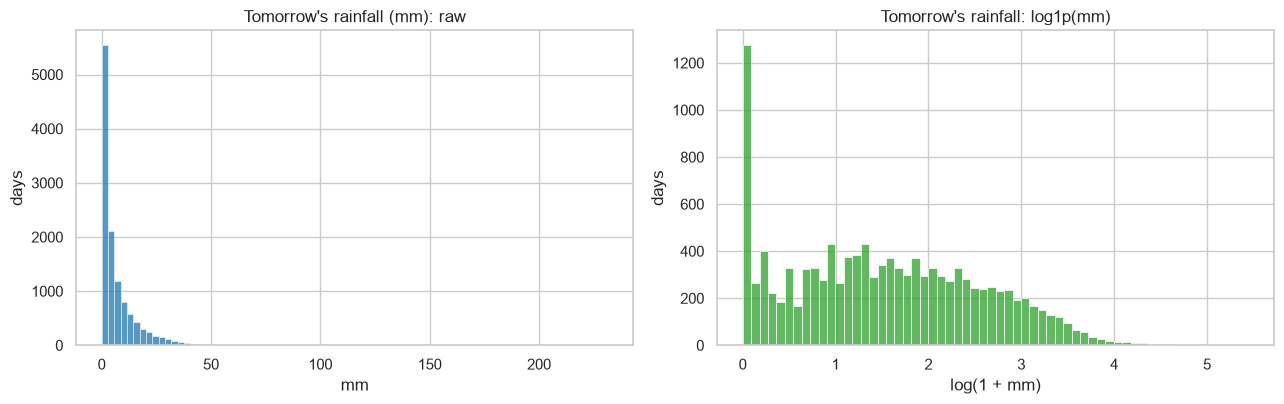

Quantiles (mm): {0.5: 3.3, 0.75: 9.0, 0.9: 18.4, 0.95: 25.7, 0.99: 43.1} | skewness raw: 5.65 | skewness log1p: 0.27


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(feat[TARGET], bins=80, ax=axes[0], color="#1f77b4")
axes[0].set(title="Tomorrow's rainfall (mm): raw", xlabel="mm", ylabel="days")
sns.histplot(np.log1p(feat[TARGET]), bins=60, ax=axes[1], color="#2ca02c")
axes[1].set(title="Tomorrow's rainfall: log1p(mm)", xlabel="log(1 + mm)", ylabel="days")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_target_distribution.png", dpi=130); plt.show()

q = feat[TARGET].quantile([.5, .75, .9, .95, .99]).round(1)
print("Quantiles (mm):", q.to_dict(), "| skewness raw:", round(feat[TARGET].skew(), 2),
      "| skewness log1p:", round(np.log1p(feat[TARGET]).skew(), 2))

**Takeaway:** rainfall is extremely right-skewed (skewness 5.65): the median day gets 3.3 mm but the wettest 1 % of days get more than 43 mm. After `log1p` the skewness drops to 0.27, almost symmetric. **Decision:** models are trained on `log1p(rain)` and predictions are converted back to mm with `expm1`. This stops a handful of flood days from dominating the squared-error loss.

### EDA 2: Monsoon climatology, the two-peak rainfall year

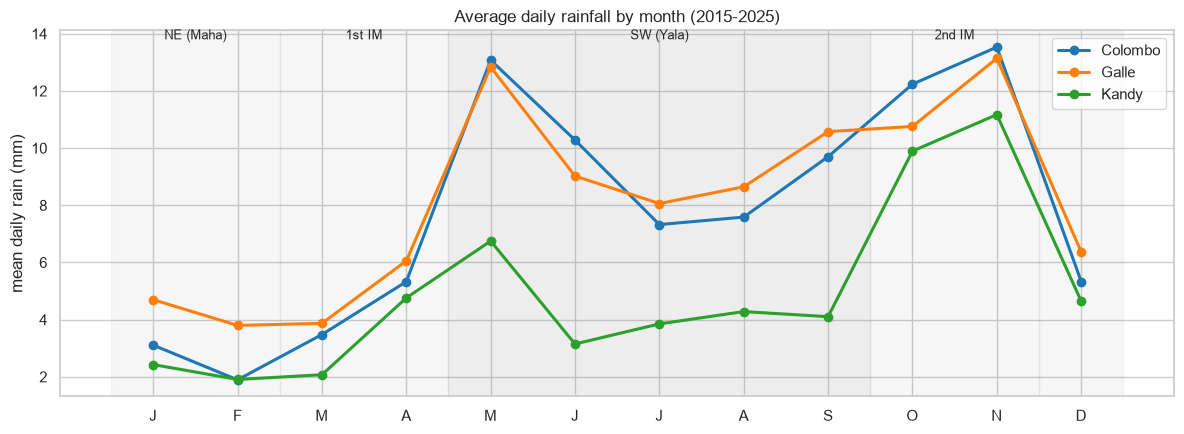

month,1,2,3,4,5,6,7,8,9,10,11,12
city,,,,,,,,,,,,
Colombo,3.1,1.9,3.5,5.3,13.1,10.3,7.3,7.6,9.7,12.2,13.5,5.3
Galle,4.7,3.8,3.9,6.1,12.8,9.0,8.1,8.6,10.6,10.8,13.1,6.4
Kandy,2.4,1.9,2.1,4.8,6.7,3.1,3.8,4.3,4.1,9.9,11.2,4.6


In [10]:
clim = df.assign(month=df["date"].dt.month).groupby(["city", "month"])["rain_mm"].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
for s, (a, b) in {"NE (Maha)": (0.5, 2.5), "1st IM": (2.5, 4.5), "SW (Yala)": (4.5, 9.5), "2nd IM": (9.5, 11.5)}.items():
    ax.axvspan(a, b, alpha=0.07 if s != "SW (Yala)" else 0.14, color="grey"); ax.text((a + b) / 2, clim["rain_mm"].max() * 1.02, s, ha="center", fontsize=9)
for city, g in clim.groupby("city"):
    ax.plot(g["month"], g["rain_mm"], marker="o", lw=2.2, label=city, color=CITY_COLORS[city])
ax.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), ylabel="mean daily rain (mm)",
       title="Average daily rainfall by month (2015-2025)")
ax.axvspan(11.5, 12.5, alpha=0.07, color="grey")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "eda_monsoon_climatology.png", dpi=130); plt.show()
clim.pivot(index="month", columns="city", values="rain_mm").round(1).T

**Takeaway:** the data reproduces Sri Lanka's textbook **two-peak rainfall year**. Colombo and Galle peak in **May** (SW monsoon onset, ~13 mm/day) and again in **October–November** (second inter-monsoon, 12–13.5 mm/day), while January–March are the driest months. Kandy, in the central hills, is in the rain shadow of the SW monsoon (only 3–4 mm/day in June–September) and gets its main rain in October–November. **The same weather can mean different things in different cities**, which is why `city`, `monsoon_season` and the seasonal terms are features, and why tree ensembles (which can learn interactions such as *season × city*) should beat linear models.

### EDA 3: Rain persistence (does today predict tomorrow?)

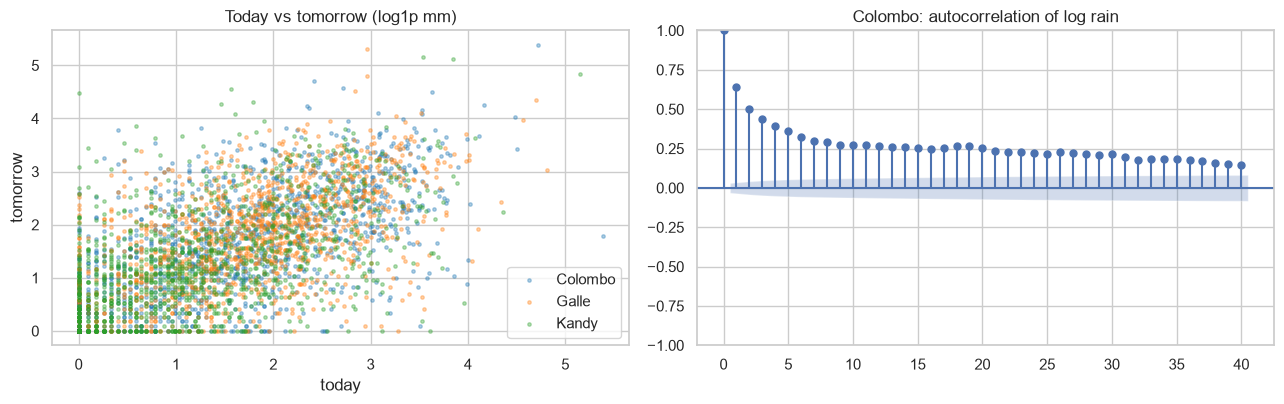

Lag-1 correlation of log rain, by city: {'Colombo': 0.639, 'Galle': 0.586, 'Kandy': 0.586}


In [11]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sample = feat.sample(4000, random_state=RANDOM_STATE)
for city, g in sample.groupby("city"):
    axes[0].scatter(np.log1p(g["rain_mm"]), np.log1p(g[TARGET]), s=6, alpha=0.35, label=city, color=CITY_COLORS[city])
axes[0].set(title="Today vs tomorrow (log1p mm)", xlabel="today", ylabel="tomorrow"); axes[0].legend()
plot_acf(np.log1p(df.loc[df.city == "Colombo", "rain_mm"]), lags=40, ax=axes[1], title="Colombo: autocorrelation of log rain")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_persistence.png", dpi=130); plt.show()

pers = feat.groupby("city").apply(lambda g: np.corrcoef(np.log1p(g["rain_mm"]), np.log1p(g[TARGET]))[0, 1])
print("Lag-1 correlation of log rain, by city:", pers.round(3).to_dict())

**Takeaway:** today's rain correlates with tomorrow's at **r ≈ 0.59–0.64** (log scale), and the autocorrelation stays positive for weeks. Wet spells and dry spells persist. This is the signal ARIMA can model, and why a **persistence baseline** ("tomorrow = today") is the bar every ensemble must beat. The scatter is also very wide, so persistence alone leaves a lot unexplained: the remaining variance must come from the atmosphere (humidity, pressure, wind) and from non-linear interactions.

### EDA 4: Which features move with tomorrow's rain?

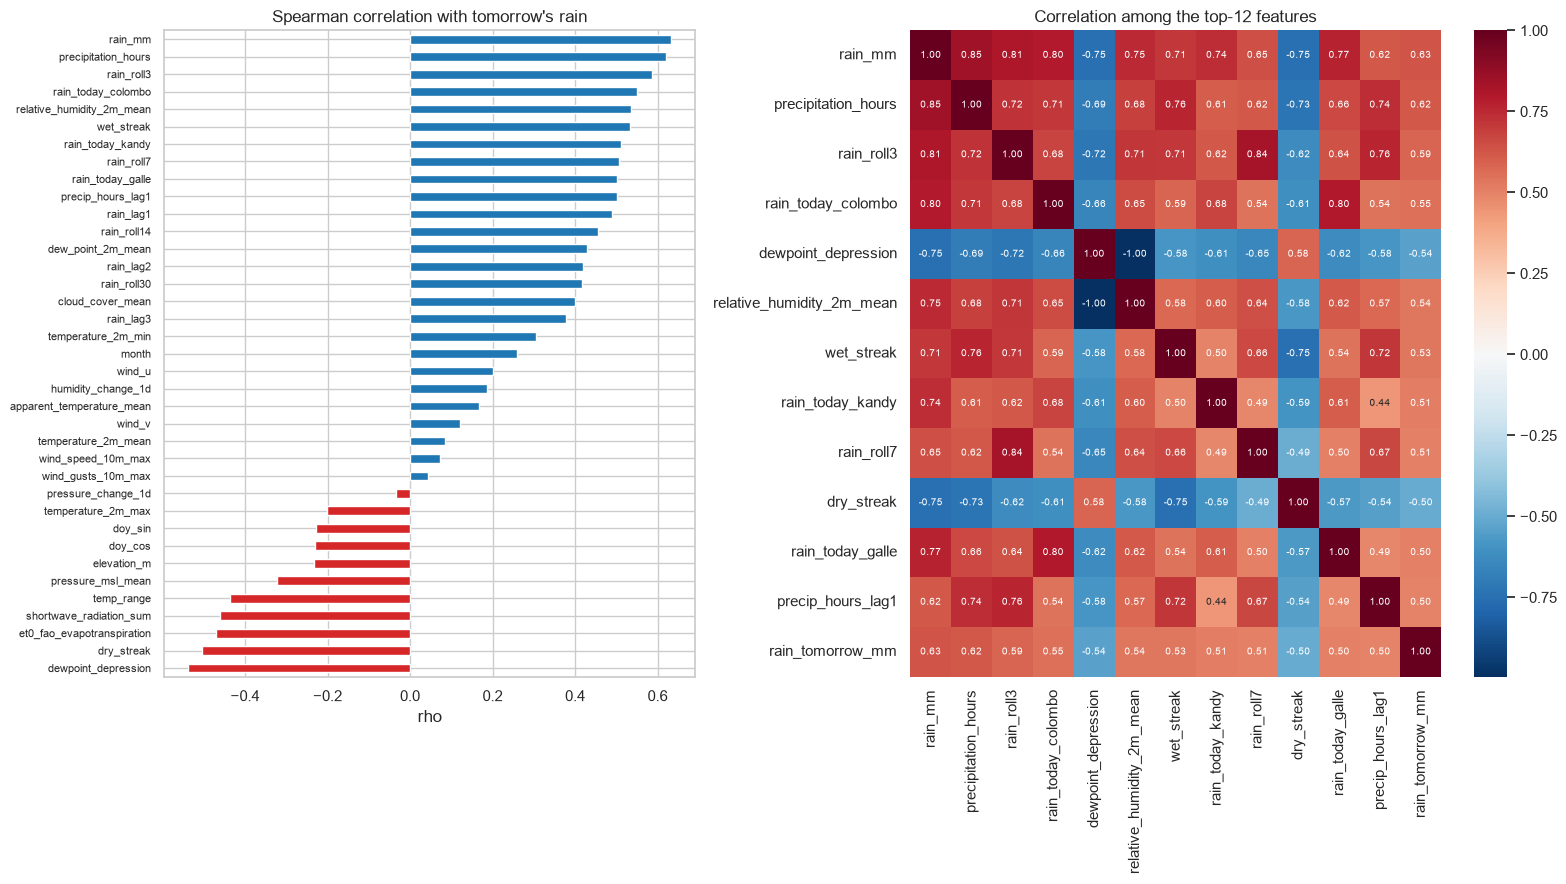

rain_mm                      0.633
precipitation_hours          0.620
rain_roll3                   0.586
rain_today_colombo           0.550
dewpoint_depression          0.537
relative_humidity_2m_mean    0.536
wet_streak                   0.532
rain_today_kandy             0.512
rain_roll7                   0.507
dry_streak                   0.504
Name: rain_tomorrow_mm, dtype: float64

In [12]:
corr = feat[NUM_FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [1, 1.25]})
corr.plot.barh(ax=axes[0], color=np.where(corr > 0, "#1f77b4", "#d62728"))
axes[0].set(title="Spearman correlation with tomorrow's rain", xlabel="rho"); axes[0].tick_params(axis="y", labelsize=8)
top = corr.abs().sort_values(ascending=False).index[:12].tolist() + [TARGET]
sns.heatmap(feat[top].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1])
axes[1].set_title("Correlation among the top-12 features")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlations.png", dpi=130); plt.show()
corr.abs().sort_values(ascending=False).head(10).round(3)

**Takeaway:** the strongest drivers are the **persistence** features (today's rain, precipitation hours, 3-day rolling mean, wet/dry streaks), the **moisture** features (humidity, dew-point depression) and the **spatial** features (today's rain in Colombo, Kandy and Galle). Rain moves across the island, so a neighbour's rain is informative. Sunshine (radiation, ET0) and a large diurnal temperature range point to *dry* tomorrows.

**Multicollinearity warning:** humidity and dew-point depression are almost perfectly correlated (ρ = −1.00), and `rain_mm`, `rain_roll3` and `precipitation_hours` overlap heavily (0.72–0.85). Tree ensembles cope with this, but it **splits feature importance between correlated twins**. We must remember this when reading SHAP plots in Section 6.

### EDA 5: Rain by monsoon season and city

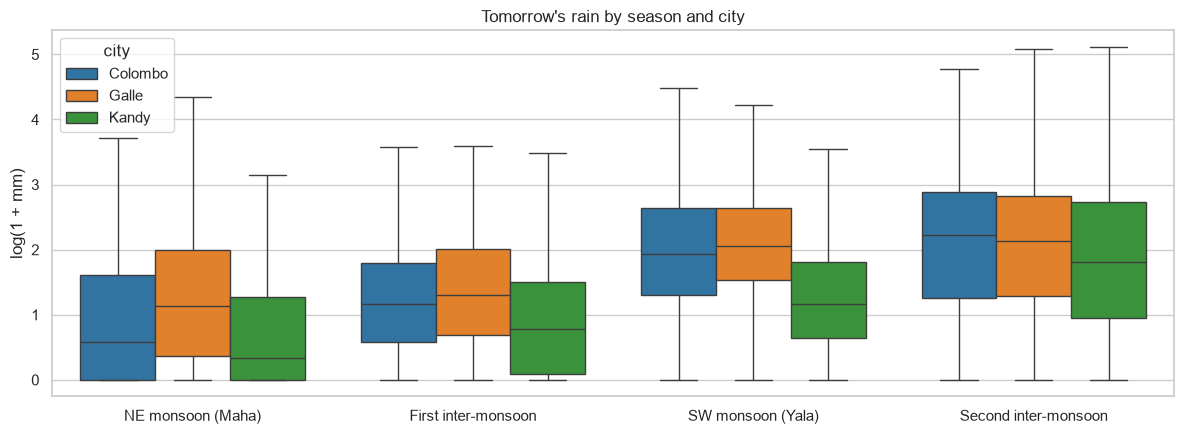

city,Colombo,Galle,Kandy
monsoon_season,,,
NE monsoon (Maha),0.105,0.161,0.091
First inter-monsoon,0.127,0.140,0.095
SW monsoon (Yala),0.334,0.340,0.114
Second inter-monsoon,0.438,0.401,0.340


In [13]:
order = ["NE monsoon (Maha)", "First inter-monsoon", "SW monsoon (Yala)", "Second inter-monsoon"]
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=feat, x="monsoon_season", y=np.log1p(feat[TARGET]), hue="city", order=order,
            palette=CITY_COLORS, showfliers=False, ax=ax)
ax.set(title="Tomorrow's rain by season and city", xlabel="", ylabel="log(1 + mm)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_season_city.png", dpi=130); plt.show()
feat.pivot_table(index="monsoon_season", columns="city", values="rain_tomorrow_event", aggfunc="mean").loc[order].round(3)

**Takeaway:** the probability of a **heavy-rain tomorrow (≥ 10 mm)** depends strongly on both season and city. On the coast it is highest in the second inter-monsoon (Colombo 44 %, Galle 40 %) and the SW monsoon (33–34 %). Kandy is only 11 % in the SW monsoon but 34 % in Oct–Nov. In the NE monsoon all three wet-zone cities are relatively dry (9–16 %). This **season × city interaction** is exactly what boosting trees capture well.

### EDA 6: Year-to-year totals (is there a trend or an anomaly?)

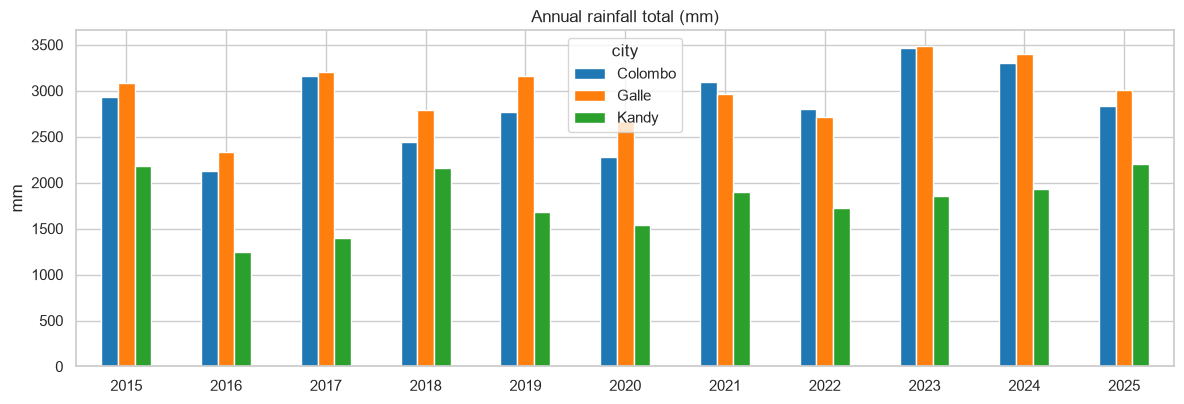

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
city,,,,,,,,,,,
Colombo,2928,2124,3155,2438,2763,2280,3096,2804,3468,3301,2828
Galle,3081,2333,3207,2787,3162,2666,2962,2719,3481,3404,3012
Kandy,2186,1248,1402,2154,1683,1534,1895,1719,1850,1930,2204


In [14]:
annual = df.assign(year=df["date"].dt.year).groupby(["year", "city"])["rain_mm"].sum().unstack()
ax = annual.plot(kind="bar", figsize=(12, 4.2), color=[CITY_COLORS[c] for c in annual.columns])
ax.set(title="Annual rainfall total (mm)", xlabel="", ylabel="mm"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_annual_totals.png", dpi=130); plt.show()
annual.round(0).astype(int).T

**Takeaway:** annual totals swing a lot between years: Colombo ranges from 2,124 mm (2016) to 3,468 mm (2023), with no clean upward or downward trend over 11 years. **2016 is the driest year for all three cities**, matching Sri Lanka's 2016–17 drought, yet 15 May 2016 is also the wettest single day in the record (231 mm in Colombo, from the depression that became **Cyclone Roanu**). The late-November 2025 extremes (217 mm in Colombo, 165 mm in Kandy) line up with **Cyclone Ditwah**. The data captures real, well-known Sri Lankan events, a good sanity check that it is genuine.

The validation year (2023) and test years (2024–2025) are **wetter than the training average** (8.1 and 7.6 mm/day vs 6.7). This is a realistic distribution shift, and it makes the test a fair and slightly harder evaluation.

### Stage 3 summary
- **Cleaned dataset:** 12,054 rows, 0 missing, 0 duplicates, 0 impossible values. One redundant column and two constant columns dropped. Real extremes kept.
- **Modeling table:** 11,964 rows × 39 features (37 numeric + `city`, `monsoon_season`). The 90 removed rows are the 30-day rolling warm-up and the last day per city (no "tomorrow").
- **Split (time-based):** train 2015-01-30 → 2022-12-31 (8,679 rows), validation 2023 (1,095), test 2024-01-01 → 2025-12-30 (2,190).
- **Target:** `rain_tomorrow_mm`, modelled as `log1p`. Secondary label `rain_tomorrow_event` (≥ 10 mm) for the dashboard's rain-alert view.

## 4. Modeling: Bagging, Boosting, Stacking and the RF + ARIMA hybrid

**Protocol (no leakage):**
1. **Phase A, model selection:** fit every model on **train (2015–2022)** and score on **validation (2023)**. Boosting models use the validation year for early stopping, which picks the number of trees.
2. **Phase B, final evaluation:** refit every model on **train + validation (2015–2023)** with the chosen settings, then score **once** on the untouched **test set (2024–2025)**.

**Target scale:** all models learn `log1p(rain)`. Every reported metric is computed in **real millimetres** after `expm1()`, with negative predictions clipped to 0.

**Preprocessing** lives inside a scikit-learn `Pipeline` / `ColumnTransformer` (one-hot for `city` and `monsoon_season`, plus scaling for the neural network), so it is fitted on training rows only.

In [15]:
import json, time, joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, roc_auc_score, f1_score
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

feat = feat.sort_values(["date", "city"]).reset_index(drop=True)   # chronological order (needed for blocked CV in stacking)
train = feat[feat.split == "train"]
valid = feat[feat.split == "valid"]
trval = feat[feat.split != "test"]
test = feat[feat.split == "test"]

def make_pre(scale=False):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("num", num, NUM_FEATURES),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)],
                             verbose_feature_names_out=False)

to_log = np.log1p
def to_mm(p):
    return np.clip(np.expm1(p), 0, None)

HEAVY = 10.0
def score(y_mm, p_mm):
    y_mm, p_mm = np.asarray(y_mm), np.asarray(p_mm)
    heavy = y_mm >= HEAVY
    return {"RMSE_mm": mean_squared_error(y_mm, p_mm) ** 0.5,
            "MAE_mm": mean_absolute_error(y_mm, p_mm),
            "R2": r2_score(y_mm, p_mm),
            "HeavyRain_AUC": roc_auc_score(heavy, p_mm),
            "HeavyRain_F1": f1_score(heavy, p_mm >= HEAVY)}
print("train", train.shape, "valid", valid.shape, "test", test.shape)

train (8679, 45) valid (1095, 45) test (2190, 45)


### 4.1 Baselines (what any model must beat)
- **Persistence:** "tomorrow's rain = today's rain". Simple, and surprisingly strong for monsoon spells.
- **Climatology:** the average rain for that city and calendar month in the training years.
- **Ridge regression:** a linear model on the same 39 features. It shows how much the *non-linear* ensembles add.

In [16]:
def baseline_preds(fit_df, eval_df):
    clim = fit_df.groupby(["city", "month"])[TARGET].mean()
    ridge = Pipeline([("pre", make_pre(scale=True)), ("model", Ridge(alpha=1.0))]).fit(fit_df[FEATURES], to_log(fit_df[TARGET]))
    return {"Persistence": eval_df["rain_mm"].values,
            "Climatology": clim.reindex(pd.MultiIndex.from_frame(eval_df[["city", "month"]])).values,
            "Ridge (linear)": to_mm(ridge.predict(eval_df[FEATURES]))}, ridge

val_preds, _ = baseline_preds(train, valid)
pd.DataFrame({k: score(valid[TARGET], v) for k, v in val_preds.items()}).T.round(3)

,RMSE_mm,MAE_mm,R2,HeavyRain_AUC,HeavyRain_F1
Persistence,9.241,5.634,0.080,0.821,0.614
Climatology,8.974,5.997,0.133,0.729,0.407
Ridge (linear),8.362,4.925,0.247,0.842,0.503


### 4.2 Bagging: Random Forest
A Random Forest grows many deep, de-correlated decision trees on **bootstrap samples** (bagging) using random feature subsets, then **averages** them. Averaging cancels the high variance of individual deep trees. Settings are kept moderate (200 trees, depth 18, leaf ≥ 8) so the saved model stays compact for deployment.

In [17]:
RF_PARAMS = dict(n_estimators=200, max_depth=18, min_samples_leaf=8, max_features=0.4, n_jobs=-1, random_state=RANDOM_STATE)
def make_rf(): return Pipeline([("pre", make_pre()), ("model", RandomForestRegressor(**RF_PARAMS))])

t0 = time.time()
rf_a = make_rf().fit(train[FEATURES], to_log(train[TARGET]))
val_preds["Random Forest (Bagging)"] = to_mm(rf_a.predict(valid[FEATURES]))
print(f"fit {time.time()-t0:.1f}s", {k: round(v, 3) for k, v in score(valid[TARGET], val_preds['Random Forest (Bagging)']).items()})

fit 1.3s {'RMSE_mm': 8.27, 'MAE_mm': 4.842, 'R2': 0.263, 'HeavyRain_AUC': 0.848, 'HeavyRain_F1': 0.54}


### 4.3 Boosting: LightGBM, XGBoost, CatBoost
Boosting builds shallow trees **sequentially**. Each new tree fits the errors (gradients) of the ensemble so far, which steadily **reduces bias**. A small learning rate plus early stopping on the 2023 validation year prevents over-fitting.
- **LightGBM:** leaf-wise growth with histogram bins. Very fast.
- **XGBoost:** level-wise growth with L1/L2 regularisation.
- **CatBoost:** symmetric (oblivious) trees and ordered boosting. Robust with little tuning.

In [18]:
pre_a = make_pre().fit(train[FEATURES])
Xtr, Xva = pre_a.transform(train[FEATURES]), pre_a.transform(valid[FEATURES])
ytr, yva = to_log(train[TARGET]).values, to_log(valid[TARGET]).values

LGB_PARAMS = dict(learning_rate=0.03, num_leaves=31, min_child_samples=30, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.7, reg_lambda=1.0, random_state=RANDOM_STATE, verbose=-1)
XGB_PARAMS = dict(learning_rate=0.03, max_depth=6, min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
                  reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1)
CAT_PARAMS = dict(learning_rate=0.03, depth=6, l2_leaf_reg=3, random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)

best_iter = {}
m = lgb.LGBMRegressor(n_estimators=3000, **LGB_PARAMS).fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(150, verbose=False)])
best_iter["LightGBM"] = m.best_iteration_
val_preds["LightGBM (Boosting)"] = to_mm(m.predict(Xva))

m = xgb.XGBRegressor(n_estimators=3000, early_stopping_rounds=150, **XGB_PARAMS).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
best_iter["XGBoost"] = m.best_iteration + 1
val_preds["XGBoost (Boosting)"] = to_mm(m.predict(Xva))

m = CatBoostRegressor(iterations=4000, od_type="Iter", od_wait=150, **CAT_PARAMS).fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True)
best_iter["CatBoost"] = m.get_best_iteration() + 1
val_preds["CatBoost (Boosting)"] = to_mm(m.predict(Xva))
print("Trees chosen by early stopping:", best_iter)

def make_lgb(): return Pipeline([("pre", make_pre()), ("model", lgb.LGBMRegressor(n_estimators=best_iter["LightGBM"], **LGB_PARAMS))])
def make_xgb(): return Pipeline([("pre", make_pre()), ("model", xgb.XGBRegressor(n_estimators=best_iter["XGBoost"], **XGB_PARAMS))])
def make_cat(): return Pipeline([("pre", make_pre()), ("model", CatBoostRegressor(iterations=best_iter["CatBoost"], **CAT_PARAMS))])

Trees chosen by early stopping: {'LightGBM': 176, 'XGBoost': 173, 'CatBoost': 290}


### 4.4 Artificial Neural Network (MLP)
A two-hidden-layer perceptron (64 → 32, ReLU) on standardised inputs, with internal early stopping. On its own it is a non-tree learner whose errors differ from the trees' errors, which makes it a valuable **diversity** member for stacking.

In [19]:
def make_mlp(): return Pipeline([("pre", make_pre(scale=True)),
                                 ("model", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3,
                                                        early_stopping=True, validation_fraction=0.15, max_iter=500,
                                                        random_state=RANDOM_STATE))])
mlp_a = make_mlp().fit(train[FEATURES], to_log(train[TARGET]))
val_preds["ANN (MLP)"] = to_mm(mlp_a.predict(valid[FEATURES]))
{k: round(v, 3) for k, v in score(valid[TARGET], val_preds["ANN (MLP)"]).items()}

{'RMSE_mm': 8.069,
 'MAE_mm': 4.798,
 'R2': 0.299,
 'HeavyRain_AUC': 0.839,
 'HeavyRain_F1': 0.563}

### 4.5 Stacking ensemble: RF + LightGBM + CatBoost + ANN → meta-learner
**Stacking** trains a *meta-learner* on the **out-of-fold** predictions of diverse base models, so it learns how much to trust each one. Base models: Random Forest (bagging), LightGBM and CatBoost (boosting), and the ANN. This is also the **RF + ANN hybrid** the brief mentions. The meta-learner is a **non-negative linear regression**, so its weights read as "how much of each model goes into the final answer".

Out-of-fold predictions use 5 **contiguous (unshuffled) folds** of the chronologically sorted data, so each fold is a block of time.

In [20]:
def make_stack():
    return StackingRegressor(
        estimators=[("rf", make_rf()), ("lgbm", make_lgb()), ("cat", make_cat()), ("ann", make_mlp())],
        final_estimator=LinearRegression(positive=True), cv=KFold(5, shuffle=False), n_jobs=1, passthrough=False)

t0 = time.time()
stack_a = make_stack().fit(train[FEATURES], to_log(train[TARGET]))
val_preds["Stacking (RF+LGBM+Cat+ANN)"] = to_mm(stack_a.predict(valid[FEATURES]))
print(f"fit {time.time()-t0:.1f}s")
print("Meta-learner weights:", dict(zip(["RF", "LightGBM", "CatBoost", "ANN"], stack_a.final_estimator_.coef_.round(3))),
      "intercept", round(stack_a.final_estimator_.intercept_, 3))

fit 16.9s
Meta-learner weights: {'RF': np.float64(0.156), 'LightGBM': np.float64(0.086), 'CatBoost': np.float64(0.568), 'ANN': np.float64(0.214)} intercept -0.041


### 4.6 Hybrid: ARIMA + Random Forest on residuals (Zhang-style hybrid)
Rainfall has a **linear, autocorrelated, seasonal** part (wet spells persist; monsoons repeat every year) and a **non-linear** part (convection triggered by humidity, wind and pressure interactions).

1. **ARIMA(2,0,1) with annual Fourier terms**, one model **per city**, on `log1p(rain)`. It is fitted on the training period only. The fitted parameters are then *applied* (not refitted) to the full series to make honest **one-step-ahead** forecasts: the forecast for day *t + 1* uses data up to day *t* only.
2. **Random Forest** learns the ARIMA **residuals** from the weather features (plus the ARIMA forecast itself).
3. **Hybrid forecast** = ARIMA forecast + RF residual correction.

This stays lightweight: 3 small ARIMA fits, a few seconds in total.

In [21]:
def fourier(index, K=2):
    doy = index.dayofyear.values
    return pd.DataFrame({f"{f}{k}": fn(2 * np.pi * k * doy / 365.25) for k in range(1, K + 1)
                         for f, fn in (("sin", np.sin), ("cos", np.cos))}, index=index)

def arima_next_day(fit_end):
    # One-step-ahead log1p forecasts of tomorrow's rain for every (city, date), params fitted up to fit_end only
    out, models = [], {}
    for city, g in df.groupby("city"):
        s = np.log1p(g.set_index("date")["rain_mm"]).asfreq("D")
        ex = fourier(s.index)
        res = ARIMA(s[:fit_end], exog=ex[:fit_end], order=(2, 0, 1)).fit()
        onestep = res.apply(s, exog=ex).predict()            # prediction for day d uses data up to d-1
        out.append(pd.DataFrame({"date": s.index, "city": city, "arima_next_log": onestep.shift(-1).values}))
        models[city] = res
    return pd.concat(out), models

RESID_FEATURES = FEATURES + ["arima_next_log"]
def make_resid_rf():
    pre = ColumnTransformer([("num", "passthrough", NUM_FEATURES + ["arima_next_log"]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)],
                            verbose_feature_names_out=False)
    return Pipeline([("pre", pre), ("model", RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                                                    max_features=0.4, n_jobs=-1, random_state=RANDOM_STATE))])

def fit_hybrid(fit_df, fit_end):
    arima_df, arima_models = arima_next_day(fit_end)
    f = fit_df.merge(arima_df, on=["date", "city"], how="left")
    rf = make_resid_rf().fit(f[RESID_FEATURES], to_log(f[TARGET]) - f["arima_next_log"])
    return arima_df, arima_models, rf

def predict_hybrid(arima_df, rf, eval_df):
    e = eval_df.merge(arima_df, on=["date", "city"], how="left")
    return to_mm(e["arima_next_log"].values), to_mm(e["arima_next_log"].values + rf.predict(e[RESID_FEATURES]))

t0 = time.time()
arima_a, arima_models_a, hyb_rf_a = fit_hybrid(train, "2022-12-31")
val_preds["ARIMA (per city)"], val_preds["Hybrid RF + ARIMA"] = predict_hybrid(arima_a, hyb_rf_a, valid)
print(f"hybrid fit {time.time()-t0:.1f}s")
for city, r in arima_models_a.items():
    print(city, "ARIMA params:", r.params.round(3).to_dict())

C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


hybrid fit 4.4s
Colombo ARIMA params: {'const': 1.565, 'sin1': -0.372, 'cos1': -0.525, 'sin2': -0.443, 'cos2': -0.172, 'ar.L1': 1.249, 'ar.L2': -0.337, 'ma.L1': -0.759, 'sigma2': 0.58}
Galle ARIMA params: {'const': 1.707, 'sin1': -0.317, 'cos1': -0.416, 'sin2': -0.301, 'cos2': -0.084, 'ar.L1': 1.017, 'ar.L2': -0.206, 'ma.L1': -0.548, 'sigma2': 0.57}
Kandy ARIMA params: {'const': 1.154, 'sin1': -0.32, 'cos1': -0.172, 'sin2': -0.346, 'cos2': -0.18, 'ar.L1': 1.099, 'ar.L2': -0.236, 'ma.L1': -0.64, 'sigma2': 0.62}


### 4.7 Retransformation bias: why `expm1(prediction)` under-forecasts, and the smearing fix
Training on `log1p(rain)` makes each model predict the **mean of log-rain**, which after `expm1` is closer to the **median** day than the **mean** day. Rain is very right-skewed, so the median is far below the mean. The models therefore **systematically under-forecast in millimetres**, and RMSE in mm (which rewards the conditional *mean*) punishes this.

The standard statistical fix is **Duan's smearing estimator**: multiply each model's back-transformed prediction by a constant factor *s* = mean(actual mm) / mean(predicted mm). We estimate one *s* per model on the **2023 validation year only** (out-of-sample), freeze it, and reuse it unchanged on the 2024–2025 test set.

In [22]:
NO_SMEAR = {"Persistence", "Climatology"}            # already in mm, not log-trained
SMEAR = {k: float(valid[TARGET].mean() / v.mean()) for k, v in val_preds.items() if k not in NO_SMEAR}
before_after = pd.DataFrame({k: {"smearing_factor": SMEAR[k],
                                 "R2_before": score(valid[TARGET], val_preds[k])["R2"],
                                 "R2_after": score(valid[TARGET], val_preds[k] * SMEAR[k])["R2"],
                                 "RMSE_before": score(valid[TARGET], val_preds[k])["RMSE_mm"],
                                 "RMSE_after": score(valid[TARGET], val_preds[k] * SMEAR[k])["RMSE_mm"]} for k in SMEAR}).T
val_preds_raw = dict(val_preds)
val_preds = {k: v * SMEAR.get(k, 1.0) for k, v in val_preds.items()}
before_after.sort_values("R2_after", ascending=False).round(3)

,smearing_factor,R2_before,R2_after,RMSE_before,RMSE_after
Stacking (RF+LGBM+Cat+ANN),1.539,0.280,0.388,8.176,7.537
LightGBM (Boosting),1.583,0.261,0.387,8.282,7.543
CatBoost (Boosting),1.577,0.257,0.385,8.305,7.554
Random Forest (Bagging),1.554,0.263,0.385,8.270,7.559
XGBoost (Boosting),1.587,0.250,0.382,8.346,7.574
Hybrid RF + ARIMA,1.552,0.261,0.375,8.282,7.615
ARIMA (per city),1.524,0.251,0.347,8.341,7.788
Ridge (linear),1.544,0.247,0.338,8.362,7.841
ANN (MLP),1.432,0.299,0.325,8.069,7.915


### 4.8 Validation leaderboard (2023, Phase A, after smearing)

In [23]:
val_table = pd.DataFrame({k: score(valid[TARGET], v) for k, v in val_preds.items()}).T.sort_values("RMSE_mm")
val_table.round(3)

,RMSE_mm,MAE_mm,R2,HeavyRain_AUC,HeavyRain_F1
Stacking (RF+LGBM+Cat+ANN),7.537,4.920,0.388,0.850,0.659
LightGBM (Boosting),7.543,4.962,0.387,0.847,0.648
CatBoost (Boosting),7.554,4.956,0.385,0.850,0.660
Random Forest (Bagging),7.559,4.975,0.385,0.848,0.646
XGBoost (Boosting),7.574,5.022,0.382,0.846,0.636
Hybrid RF + ARIMA,7.615,4.993,0.375,0.845,0.654
ARIMA (per city),7.788,5.132,0.347,0.834,0.651
Ridge (linear),7.841,5.057,0.338,0.842,0.644
ANN (MLP),7.915,5.063,0.325,0.839,0.658
Climatology,8.974,5.997,0.133,0.729,0.407


## 5. Final evaluation on the untouched test set (2024–2025)
All models are refitted on **2015–2023** with the settings chosen above, then scored once on **2,190 unseen days**. Metrics are in **millimetres**.

In [24]:
t0 = time.time()
final_models = {}
test_preds, ridge_b = baseline_preds(trval, test)
final_models["Ridge (linear)"] = ridge_b

for name, maker in [("Random Forest (Bagging)", make_rf), ("LightGBM (Boosting)", make_lgb), ("XGBoost (Boosting)", make_xgb),
                    ("CatBoost (Boosting)", make_cat), ("ANN (MLP)", make_mlp), ("Stacking (RF+LGBM+Cat+ANN)", make_stack)]:
    t1 = time.time()
    final_models[name] = maker().fit(trval[FEATURES], to_log(trval[TARGET]))
    test_preds[name] = to_mm(final_models[name].predict(test[FEATURES]))
    print(f"{name:30s} fitted in {time.time()-t1:5.1f}s")

arima_b, arima_models_b, hyb_rf_b = fit_hybrid(trval, "2023-12-31")
test_preds["ARIMA (per city)"], test_preds["Hybrid RF + ARIMA"] = predict_hybrid(arima_b, hyb_rf_b, test)
print(f"total {time.time()-t0:.1f}s")
test_preds_raw = dict(test_preds)
test_preds = {k: v * SMEAR.get(k, 1.0) for k, v in test_preds.items()}   # frozen factors from validation

FAMILY = {"Persistence": "Baseline", "Climatology": "Baseline", "Ridge (linear)": "Baseline", "ANN (MLP)": "Neural net",
          "Random Forest (Bagging)": "Bagging", "LightGBM (Boosting)": "Boosting", "XGBoost (Boosting)": "Boosting",
          "CatBoost (Boosting)": "Boosting", "Stacking (RF+LGBM+Cat+ANN)": "Stacking", "ARIMA (per city)": "Time-series",
          "Hybrid RF + ARIMA": "Hybrid"}
test_table = pd.DataFrame({k: score(test[TARGET], v) for k, v in test_preds.items()}).T
test_table.insert(0, "Family", test_table.index.map(FAMILY))
test_table = test_table.sort_values("RMSE_mm")
persist_rmse = test_table.loc["Persistence", "RMSE_mm"]
test_table["RMSE_gain_vs_persistence_%"] = 100 * (1 - test_table["RMSE_mm"] / persist_rmse)
test_table["R2_without_smearing"] = [r2_score(test[TARGET], test_preds_raw[k]) for k in test_table.index]
test_table.round(3)

Random Forest (Bagging)        fitted in   1.3s


LightGBM (Boosting)            fitted in   0.3s


XGBoost (Boosting)             fitted in   0.5s


CatBoost (Boosting)            fitted in   1.2s


ANN (MLP)                      fitted in   0.7s


Stacking (RF+LGBM+Cat+ANN)     fitted in  19.4s


C:\Users\Sineth\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


total 27.4s


,Family,RMSE_mm,MAE_mm,R2,HeavyRain_AUC,HeavyRain_F1,RMSE_gain_vs_persistence_%,R2_without_smearing
XGBoost (Boosting),Boosting,9.754,5.458,0.346,0.824,0.583,18.058,0.250
Random Forest (Bagging),Bagging,9.915,5.415,0.324,0.823,0.577,16.711,0.226
LightGBM (Boosting),Boosting,9.921,5.511,0.324,0.823,0.576,16.661,0.247
Stacking (RF+LGBM+Cat+ANN),Stacking,9.948,5.469,0.320,0.825,0.586,16.432,0.250
CatBoost (Boosting),Boosting,9.978,5.425,0.316,0.824,0.568,16.176,0.222
Hybrid RF + ARIMA,Hybrid,10.023,5.459,0.309,0.819,0.580,15.798,0.227
Ridge (linear),Baseline,10.185,5.712,0.287,0.817,0.567,14.441,0.284
ARIMA (per city),Time-series,10.265,5.581,0.276,0.802,0.554,13.766,0.196
ANN (MLP),Neural net,10.559,5.911,0.234,0.813,0.591,11.301,0.250
Climatology,Baseline,11.586,6.539,0.077,0.667,0.368,2.669,0.077


Final stacking meta-weights: {'Random Forest': np.float64(0.067), 'LightGBM': np.float64(0.281), 'CatBoost': np.float64(0.447), 'ANN': np.float64(0.23)}


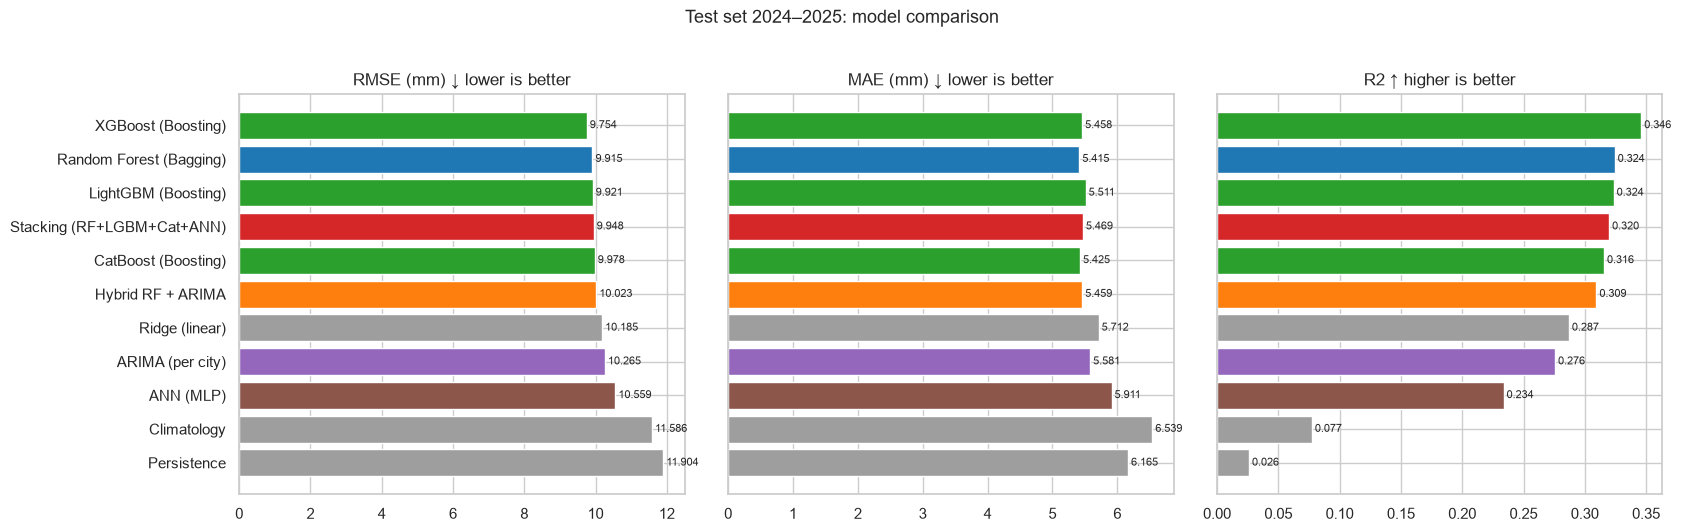

In [25]:
stack_w = dict(zip(["Random Forest", "LightGBM", "CatBoost", "ANN"], final_models["Stacking (RF+LGBM+Cat+ANN)"].final_estimator_.coef_))
print("Final stacking meta-weights:", {k: round(v, 3) for k, v in stack_w.items()})

# Comparison chart
plot_t = test_table.sort_values("RMSE_mm", ascending=False)
fam_colors = {"Baseline": "#9e9e9e", "Neural net": "#8c564b", "Bagging": "#1f77b4", "Boosting": "#2ca02c",
              "Stacking": "#d62728", "Time-series": "#9467bd", "Hybrid": "#ff7f0e"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
for ax, col in zip(axes, ["RMSE_mm", "MAE_mm", "R2"]):
    ax.barh(plot_t.index, plot_t[col], color=plot_t["Family"].map(fam_colors))
    for y, v in enumerate(plot_t[col]): ax.text(v, y, f" {v:.3f}", va="center", fontsize=8)
    ax.set_title(col.replace("_mm", " (mm)") + (" ↓ lower is better" if col != "R2" else " ↑ higher is better"))
plt.suptitle("Test set 2024–2025: model comparison", y=1.02, fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR / "model_comparison.png", dpi=130, bbox_inches="tight"); plt.show()

### 5.0 Are the differences between ensembles real? (paired bootstrap)
The ensembles are close together, so we test whether the gaps are larger than sampling noise. We resample the 730 test **dates** with replacement (all three cities of a date stay together, keeping spatial correlation) 1,000 times, and record each model's RMSE minus the best model's RMSE.

In [26]:
rng = np.random.RandomState(RANDOM_STATE)
dates = test["date"].values; uniq = np.unique(dates)
pos_by_date = {d: np.where(dates == d)[0] for d in uniq}
best_ref = test_table.index[0]
y_t = test[TARGET].values
boot = {k: [] for k in test_table.index if k != best_ref}
for _ in range(1000):
    idx = np.concatenate([pos_by_date[d] for d in rng.choice(uniq, len(uniq), replace=True)])
    ref = mean_squared_error(y_t[idx], test_preds[best_ref][idx]) ** 0.5
    for k in boot:
        boot[k].append(mean_squared_error(y_t[idx], test_preds[k][idx]) ** 0.5 - ref)
sig = pd.DataFrame({k: {"mean_RMSE_gap_mm": np.mean(v), "CI95_low": np.percentile(v, 2.5), "CI95_high": np.percentile(v, 97.5),
                        "P(model beats " + best_ref.split(" (")[0] + ")": np.mean(np.array(v) < 0)} for k, v in boot.items()}).T
sig["significantly_worse"] = sig["CI95_low"] > 0
sig.sort_values("mean_RMSE_gap_mm").round(3)

,mean_RMSE_gap_mm,CI95_low,CI95_high,P(model beats XGBoost),significantly_worse
Random Forest (Bagging),0.149,-0.028,0.334,0.054,False
LightGBM (Boosting),0.165,0.045,0.298,0.002,True
Stacking (RF+LGBM+Cat+ANN),0.187,-0.033,0.484,0.068,False
CatBoost (Boosting),0.208,-0.051,0.584,0.109,False
Hybrid RF + ARIMA,0.258,0.013,0.561,0.021,True
Ridge (linear),0.454,-0.744,2.116,0.344,False
ARIMA (per city),0.497,0.129,0.917,0.002,True
ANN (MLP),0.812,0.298,1.361,0.000,True
Climatology,1.790,1.032,2.760,0.000,True
Persistence,2.166,0.162,4.887,0.014,True


### 5.0b How much of the error comes from a few cyclone days?

In [27]:
cut = test[TARGET].quantile(0.99); normal = (test[TARGET] < cut).values
ext = pd.DataFrame({k: {"RMSE_all_days": mean_squared_error(y_t, p) ** 0.5,
                        "RMSE_without_top1pct": mean_squared_error(y_t[normal], p[normal]) ** 0.5,
                        "share_of_squared_error_from_top1pct": ((y_t - p)[~normal] ** 2).sum() / ((y_t - p) ** 2).sum(),
                        "max_prediction_mm": p.max()} for k, p in test_preds.items()}).T.sort_values("RMSE_without_top1pct")
print(f"Top 1% threshold: {cut:.1f} mm ({(~normal).sum()} of {len(normal)} test rows)")
display(ext.round(3))
worst = test.assign(**{k: test_preds[k] for k in ["XGBoost (Boosting)", "Stacking (RF+LGBM+Cat+ANN)", "Ridge (linear)", "Persistence"]})
worst.nlargest(5, TARGET)[["date", "city", TARGET, "XGBoost (Boosting)", "Stacking (RF+LGBM+Cat+ANN)", "Ridge (linear)", "Persistence"]].round(1)

Top 1% threshold: 48.5 mm (22 of 2190 test rows)


,RMSE_all_days,RMSE_without_top1pct,share_of_squared_error_from_top1pct,max_prediction_mm
Random Forest (Bagging),9.915,7.257,0.470,51.542
CatBoost (Boosting),9.978,7.262,0.476,44.136
XGBoost (Boosting),9.754,7.297,0.446,66.104
Stacking (RF+LGBM+Cat+ANN),9.948,7.348,0.460,50.045
Hybrid RF + ARIMA,10.023,7.404,0.460,48.531
LightGBM (Boosting),9.921,7.421,0.446,55.794
ARIMA (per city),10.265,7.624,0.454,58.782
ANN (MLP),10.559,8.066,0.422,70.471
Climatology,11.586,8.340,0.487,13.049
Ridge (linear),10.185,8.459,0.317,149.793


,date,city,rain_tomorrow_mm,XGBoost (Boosting),Stacking (RF+LGBM+Cat+ANN),Ridge (linear),Persistence
11862,2025-11-27,Colombo,217.5,66.099998,48.2,90.7,111.1
11861,2025-11-26,Kandy,164.9,21.000000,22.5,36.9,45.9
11864,2025-11-27,Kandy,138.6,48.000000,43.9,149.8,164.9
11859,2025-11-26,Colombo,111.1,18.000000,18.9,17.6,17.6
11860,2025-11-26,Galle,95.6,16.799999,21.2,28.4,31.4


### 5.1 Where do the models win or lose? (by city and by season)

In [28]:
best_name = test_table.drop(index=["Persistence", "Climatology", "Ridge (linear)"]).index[0]
compare = ["Persistence", "Random Forest (Bagging)", "LightGBM (Boosting)", "Stacking (RF+LGBM+Cat+ANN)", "Hybrid RF + ARIMA"]
rows = []
for grp_col in ["city", "monsoon_season"]:
    for grp, idx in test.groupby(grp_col).groups.items():
        pos = test.index.get_indexer(idx)
        for mname in compare:
            rows.append({"by": grp_col, "group": grp, "model": mname,
                         "RMSE_mm": mean_squared_error(test[TARGET].iloc[pos], test_preds[mname][pos]) ** 0.5})
seg = pd.DataFrame(rows).pivot_table(index=["by", "group"], columns="model", values="RMSE_mm")[compare]
print("Best non-baseline model on test:", best_name)
seg.round(2)

Best non-baseline model on test: XGBoost (Boosting)


model                                Persistence  Random Forest (Bagging)  \
by             group                                                        
city           Colombo                     13.57                    10.78   
               Galle                       10.79                     8.87   
               Kandy                       11.16                     9.99   
monsoon_season First inter-monsoon          6.89                     5.40   
               NE monsoon (Maha)            9.31                     7.37   
               SW monsoon (Yala)            9.77                     8.05   
               Second inter-monsoon        20.80                    17.78   

model                                LightGBM (Boosting)  \
by             group                                       
city           Colombo                             10.71   
               Galle                                8.98   
               Kandy                               10.00   
monsoon_season First inter-monsoon                  5.48   
               NE monsoon (Maha)                    7.35   
               SW monsoon (Yala)                    8.10   
               Second inter-monsoon                17.74   

model                                Stacking (RF+LGBM+Cat+ANN)  \
by             group                                              
city           Colombo                                    10.87   
               Galle                                       8.95   
               Kandy                                       9.94   
monsoon_season First inter-monsoon                         5.43   
               NE monsoon (Maha)                           7.31   
               SW monsoon (Yala)                           8.21   
               Second inter-monsoon                       17.75   

model                                Hybrid RF + ARIMA  
by             group                                    
city           Colombo                           11.02  
               Galle                              8.89  
               Kandy                             10.05  
monsoon_season First inter-monsoon                5.58  
               NE monsoon (Maha)                  7.42  
               SW monsoon (Yala)                  8.06  
               Second inter-monsoon              18.05

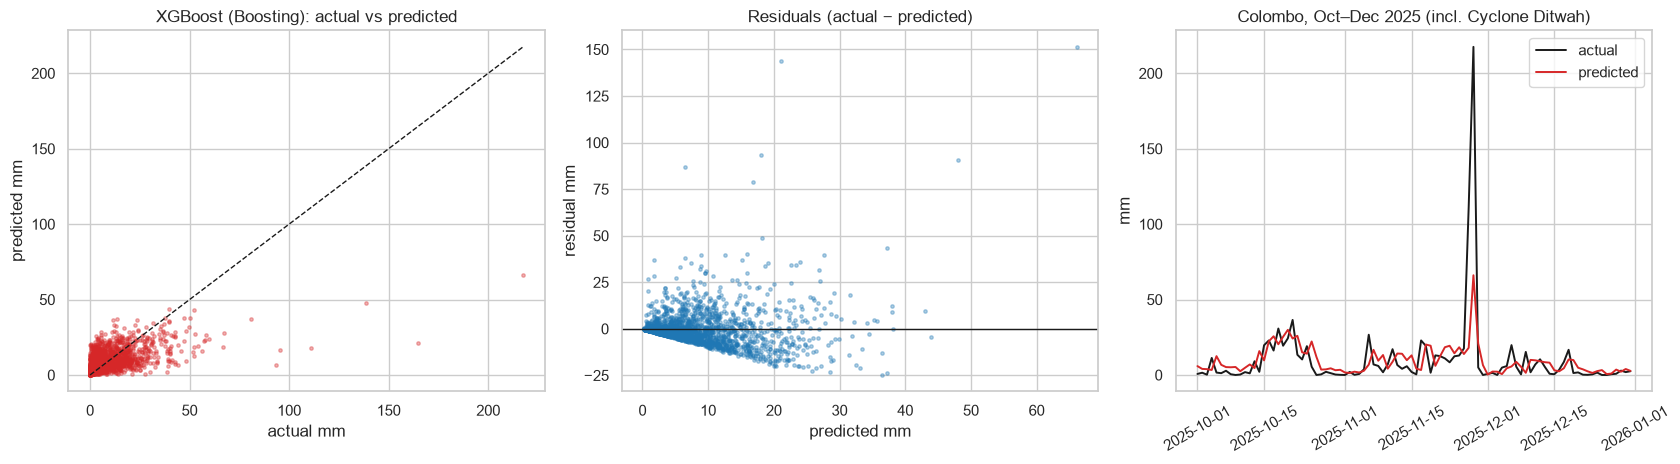

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
p = test_preds[best_name]; y = test[TARGET].values
axes[0].scatter(y, p, s=6, alpha=0.35, color="#d62728"); lim = max(y.max(), p.max())
axes[0].plot([0, lim], [0, lim], "k--", lw=1); axes[0].set(title=f"{best_name}: actual vs predicted", xlabel="actual mm", ylabel="predicted mm")
axes[1].scatter(p, y - p, s=6, alpha=0.35, color="#1f77b4"); axes[1].axhline(0, color="k", lw=1)
axes[1].set(title="Residuals (actual − predicted)", xlabel="predicted mm", ylabel="residual mm")
col = test[test.city == "Colombo"].index; pos = test.index.get_indexer(col)
d = test.loc[col, "date"] + pd.Timedelta(days=1)
mask = (d >= "2025-10-01") & (d <= "2025-12-31")
axes[2].plot(d[mask], y[pos][mask], label="actual", color="k", lw=1.4)
axes[2].plot(d[mask], p[pos][mask], label="predicted", color="#d62728", lw=1.4)
axes[2].set(title="Colombo, Oct–Dec 2025 (incl. Cyclone Ditwah)", ylabel="mm"); axes[2].legend(); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR / "actual_vs_predicted.png", dpi=130); plt.show()

## 6. Explainability: SHAP and feature importance
SHAP (SHapley Additive exPlanations) splits each prediction into a contribution per feature, measured in **log-rain units** relative to the average prediction. We explain the **LightGBM** model (the fastest exact `TreeExplainer`), and compare it with the Random Forest's impurity importance.

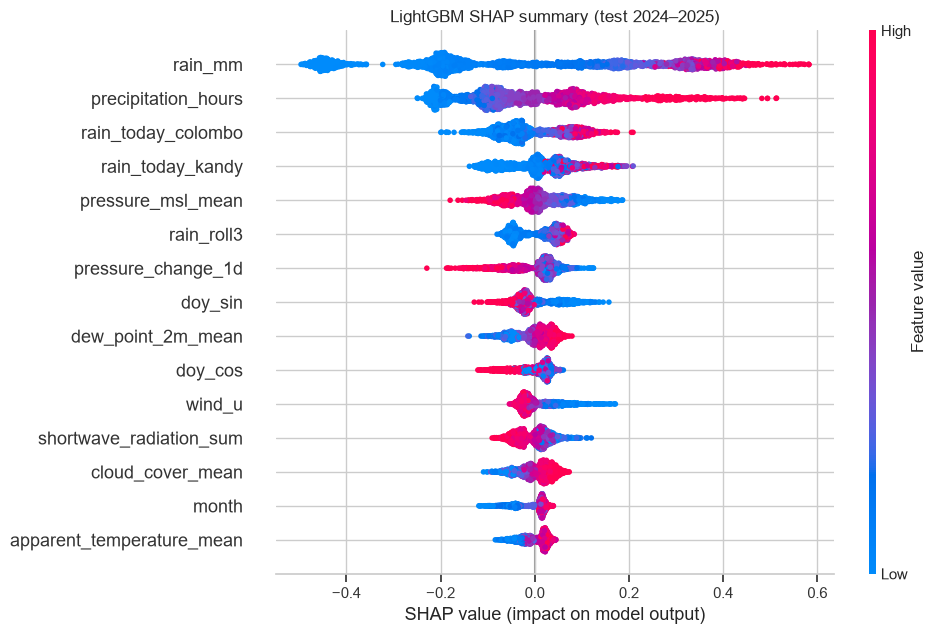

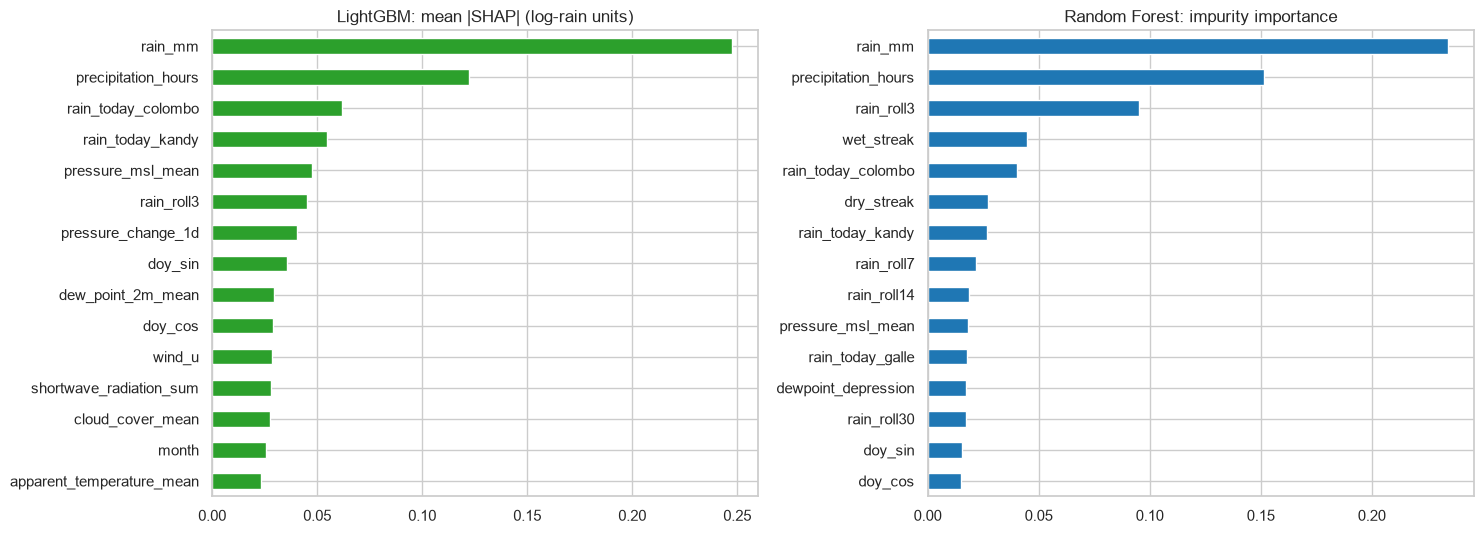

,mean_abs_SHAP_lgbm,RF_importance
rain_mm,0.2477,0.2343
precipitation_hours,0.1223,0.1515
rain_today_colombo,0.0618,0.0403
rain_today_kandy,0.0545,0.0269
pressure_msl_mean,0.0476,0.0180
rain_roll3,0.0449,0.0953
pressure_change_1d,0.0404,0.0138
doy_sin,0.0357,0.0154
dew_point_2m_mean,0.0293,0.0149
doy_cos,0.0288,0.0151


In [30]:
import shap
lgb_pipe = final_models["LightGBM (Boosting)"]
X_test_t = pd.DataFrame(lgb_pipe.named_steps["pre"].transform(test[FEATURES]), columns=lgb_pipe.named_steps["pre"].get_feature_names_out())
explainer = shap.TreeExplainer(lgb_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_t)

shap_imp = pd.Series(np.abs(shap_values).mean(0), index=X_test_t.columns).sort_values(ascending=False)
rf_model = final_models["Random Forest (Bagging)"]
rf_imp = pd.Series(rf_model.named_steps["model"].feature_importances_, index=rf_model.named_steps["pre"].get_feature_names_out())

shap.summary_plot(shap_values, X_test_t, max_display=15, show=False, plot_size=(10, 6.5))
plt.title("LightGBM SHAP summary (test 2024–2025)"); plt.tight_layout(); plt.savefig(FIG_DIR / "shap_summary.png", dpi=130, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
shap_imp.head(15)[::-1].plot.barh(ax=axes[0], color="#2ca02c"); axes[0].set(title="LightGBM: mean |SHAP| (log-rain units)")
rf_imp.sort_values(ascending=False).head(15)[::-1].plot.barh(ax=axes[1], color="#1f77b4"); axes[1].set(title="Random Forest: impurity importance")
plt.tight_layout(); plt.savefig(FIG_DIR / "feature_importance.png", dpi=130); plt.show()
pd.DataFrame({"mean_abs_SHAP_lgbm": shap_imp, "RF_importance": rf_imp}).sort_values("mean_abs_SHAP_lgbm", ascending=False).head(12).round(4)

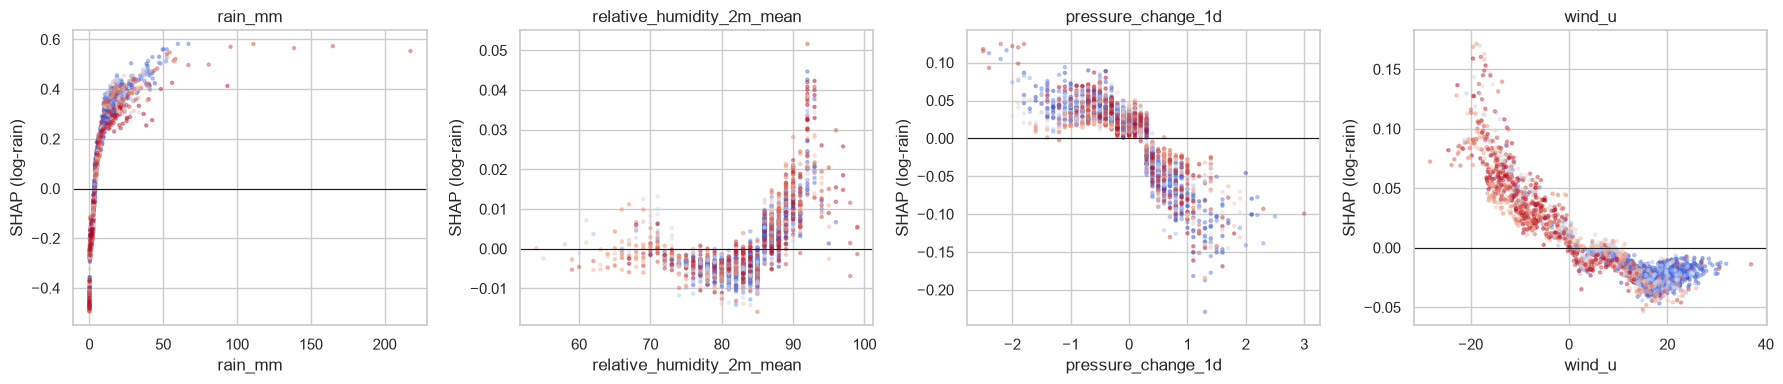

,Colombo,Kandy,Galle
rain_mm,0.2521,0.2503,0.2407
precipitation_hours,0.1255,0.1229,0.1186
rain_today_colombo,0.0641,0.0494,0.0719
rain_today_kandy,0.0569,0.0499,0.0568
pressure_msl_mean,0.0486,0.0486,0.0456
rain_roll3,0.0467,0.0423,0.0459
pressure_change_1d,0.0407,0.0373,0.0432
doy_sin,0.0352,0.0372,0.0347
dew_point_2m_mean,0.0260,0.0384,0.0235
doy_cos,0.0299,0.0283,0.0281


In [31]:
# How do the top drivers act? SHAP dependence for four key features
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, ["rain_mm", "relative_humidity_2m_mean", "pressure_change_1d", "wind_u"]):
    ax.scatter(X_test_t[f], shap_values[:, X_test_t.columns.get_loc(f)], s=5, alpha=0.4, c=X_test_t["doy_cos"], cmap="coolwarm")
    ax.axhline(0, color="k", lw=0.8); ax.set(title=f, xlabel=f, ylabel="SHAP (log-rain)")
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_dependence.png", dpi=130); plt.show()

# SHAP importance by city: does the model reason differently for Kandy?
city_shap = pd.DataFrame({c: np.abs(shap_values[test["city"].values == c]).mean(0) for c in ["Colombo", "Kandy", "Galle"]},
                         index=X_test_t.columns)
city_shap.loc[shap_imp.index[:10]].round(4)

## 7. Save models and artefacts for the dashboard

In [32]:
MODELS_DIR.mkdir(exist_ok=True)
save_map = {"Ridge (linear)": "ridge", "Random Forest (Bagging)": "random_forest", "LightGBM (Boosting)": "lightgbm",
            "XGBoost (Boosting)": "xgboost", "CatBoost (Boosting)": "catboost", "ANN (MLP)": "ann_mlp",
            "Stacking (RF+LGBM+Cat+ANN)": "stacking"}
for name, fname in save_map.items():
    joblib.dump(final_models[name], MODELS_DIR / f"{fname}.joblib", compress=3)
joblib.dump(hyb_rf_b, MODELS_DIR / "hybrid_residual_rf.joblib", compress=3)
for city, r in arima_models_b.items():
    r.remove_data()
    joblib.dump(r, MODELS_DIR / f"arima_{city.lower()}.joblib", compress=3)

# Per-row test predictions (incl. the ARIMA component) so the dashboard needs no retraining
pred_df = test[["date", "city", "monsoon_season", TARGET]].copy().reset_index(drop=True)
for name, p in test_preds.items():
    pred_df[name] = np.round(p, 3)
pred_df = pred_df.merge(arima_b, on=["date", "city"], how="left")
pred_df.to_csv(MODELS_DIR / "test_predictions.csv", index=False)

# Compact SHAP data: global importance + a 600-row sample for the beeswarm
shap_imp.rename("mean_abs_shap").to_csv(MODELS_DIR / "shap_importance.csv")
samp = np.random.RandomState(RANDOM_STATE).choice(len(X_test_t), 600, replace=False)
top_cols = shap_imp.index[:12]
pd.concat([X_test_t.iloc[samp][top_cols].add_prefix("x__").reset_index(drop=True),
           pd.DataFrame(shap_values[samp][:, [X_test_t.columns.get_loc(c) for c in top_cols]], columns=top_cols).add_prefix("s__")],
          axis=1).to_csv(MODELS_DIR / "shap_sample.csv", index=False)
rf_imp.rename("rf_importance").to_csv(MODELS_DIR / "rf_importance.csv")

metrics = {
    "target": TARGET, "units": "mm (metrics computed after expm1 inverse transform, clipped at 0)",
    "heavy_rain_threshold_mm": HEAVY,
    "split": {s: {"rows": int((feat.split == s).sum()), "start": str(feat.loc[feat.split == s, "date"].min().date()),
                  "end": str(feat.loc[feat.split == s, "date"].max().date())} for s in ["train", "valid", "test"]},
    "best_model": best_name,
    "test": {k: {m: (v if isinstance(v, str) else round(float(v), 4)) for m, v in row.items()} for k, row in test_table.iterrows()},
    "validation_smearing": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in before_after.iterrows()},
    "validation": {k: {m: round(float(v), 4) for m, v in row.items()} for k, row in val_table.iterrows()},
    "smearing_factors": {k: round(v, 4) for k, v in SMEAR.items()},
    "boosting_trees": {k: int(v) for k, v in best_iter.items()},
    "stacking_weights": {k: round(float(v), 4) for k, v in stack_w.items()},
    "bootstrap_vs_best": {k: {m: (bool(v) if isinstance(v, (bool, np.bool_)) else round(float(v), 4)) for m, v in r.items()} for k, r in sig.iterrows()},
    "extreme_days": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in ext.iterrows()},
    "segment_rmse": {f"{b}|{g}": {m: round(float(v), 3) for m, v in r.items()} for (b, g), r in seg.iterrows()},
    "features": {"numeric": NUM_FEATURES, "categorical": CAT_FEATURES, "hybrid_extra": ["arima_next_log"]},
    "model_files": {**{n: f"{f}.joblib" for n, f in save_map.items()}, "Hybrid RF + ARIMA": "hybrid_residual_rf.joblib"},
}
(MODELS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
(MODELS_DIR / "feature_list.json").write_text(json.dumps(metrics["features"], indent=2))

sizes = pd.Series({p.name: p.stat().st_size / 1e6 for p in MODELS_DIR.iterdir() if p.is_file()}).sort_values(ascending=False)
print(f"Saved {len(sizes)} files, total {sizes.sum():.1f} MB"); sizes.round(2)

Saved 18 files, total 18.5 MB


stacking.joblib              6.77
random_forest.joblib         6.27
hybrid_residual_rf.joblib    2.88
arima_galle.joblib           0.44
arima_colombo.joblib         0.44
arima_kandy.joblib           0.43
test_predictions.csv         0.28
xgboost.joblib               0.24
shap_sample.csv              0.23
lightgbm.joblib              0.19
catboost.joblib              0.16
ann_mlp.joblib               0.12
metrics.json                 0.02
ridge.joblib                 0.00
rf_importance.csv            0.00
shap_importance.csv          0.00
feature_list.json            0.00
.gitkeep                     0.00
dtype: float64

## 8. Interpretation: why the models performed the way they did

### Final test results (2024–2025, 2,190 unseen city-days, metrics in mm)

| Rank | Model | Family | RMSE (mm) | MAE (mm) | R² | Heavy-rain AUC |
|---|---|---|---|---|---|---|
| 1 | **XGBoost** | Boosting | **9.75** | 5.46 | **0.346** | 0.824 |
| 2 | Random Forest | Bagging | 9.92 | **5.42** | 0.324 | 0.823 |
| 3 | LightGBM | Boosting | 9.92 | 5.51 | 0.324 | 0.823 |
| 4 | Stacking (RF + LGBM + Cat + ANN) | Stacking | 9.95 | 5.47 | 0.320 | **0.825** |
| 5 | CatBoost | Boosting | 9.98 | 5.43 | 0.316 | 0.824 |
| 6 | Hybrid RF + ARIMA | Hybrid | 10.02 | 5.46 | 0.309 | 0.819 |
| 7 | Ridge (linear) | Baseline | 10.19 | 5.71 | 0.287 | 0.817 |
| 8 | ARIMA (per city) | Time-series | 10.27 | 5.58 | 0.276 | 0.802 |
| 9 | ANN (MLP) | Neural net | 10.56 | 5.91 | 0.234 | 0.813 |
| 10 | Climatology | Baseline | 11.59 | 6.54 | 0.077 | 0.667 |
| 11 | Persistence | Baseline | 11.90 | 6.17 | 0.026 | 0.803 |

### 1. Every ensemble clearly beats the baselines, because rain is non-linear
All six tree ensembles cut RMSE by **16–18 % against persistence** and lift R² from 0.03 to **0.31–0.35**. The SHAP dependence plots show *why* linear models fall short:
- **Today's rain** has a strongly **saturating** effect: the first 10 mm of rain today raises tomorrow's forecast sharply, but beyond about 50 mm the effect flattens out.
- **Humidity** does almost nothing below about 85 % and then switches on sharply above 88–90 %, a **threshold** effect that is typical of convective (thunderstorm) rain.
- **Falling pressure** (`pressure_change_1d` < 0) pushes the forecast up, and **rising pressure** pushes it down. This is the classic signature of an approaching low or depression.
- **Easterly winds** (`wind_u` < 0, mostly in the Oct–Jan season) add rain. These are the NE monsoon and Bay of Bengal depressions.

Decision trees capture saturation, thresholds and **season × city interactions** natively. A linear model needs every one of these to be hand-crafted.

### 2. Boosting vs bagging: a bias–variance story
- **Random Forest (bagging)** averages 200 deep, de-correlated trees, which **lowers variance**. It has the **lowest MAE (5.42 mm)**: it is very good on typical days.
- **XGBoost (boosting)** adds shallow trees sequentially, each fixing the residuals of the previous ones, which **lowers bias**. It reaches further into the tail (largest prediction 66 mm vs 52 mm for RF), so it loses less on the big days and wins on **RMSE and R²**.
- The **paired bootstrap** (Section 5.0) shows that XGBoost beats LightGBM, the hybrid, ARIMA and the ANN significantly. Its lead over **Random Forest, Stacking and CatBoost is not statistically significant** (the 95 % intervals include 0). Honest conclusion: *the top ensembles are tied within noise; XGBoost is the best single point estimate.*

### 3. Why stacking did not win on the test set (even though it won validation)
Stacking was the **best model on the 2023 validation year** (RMSE 7.54, R² 0.388) and has the **best heavy-rain AUC** on test (0.825). On 2024–2025 it finished 4th, 0.19 mm behind XGBoost (not significant). Reasons:
1. **Low diversity:** the RF, LightGBM and CatBoost base learners see the same features and make highly correlated errors. Stacking only gains when base models are *wrong in different ways*. The meta-learner weights (CatBoost 0.45, LightGBM 0.28, ANN 0.23, RF 0.07) show it leaned on CatBoost, plus the ANN for diversity.
2. **The test years are different:** the test period contains **Cyclone Ditwah (Nov 2025)**, which is far more extreme than anything in 2023. A meta-learner tuned to blend models for "normal" years cannot extrapolate.
3. **Averaging shrinks extremes:** blending several conservative models gives an even more conservative forecast (maximum about 50 mm), which RMSE punishes on flood days.

### 4. The RF + ARIMA hybrid: the theory works, but the margin is small
ARIMA alone (AR(1) coefficients 1.02–1.25 plus annual Fourier terms) captures **persistence and seasonality** and already beats persistence by 14 %. Adding a Random Forest on its residuals improves RMSE from **10.27 to 10.02 mm** (R² 0.276 → 0.309). That confirms the Zhang hybrid idea: *a linear time-series model plus a non-linear residual learner beats either alone*. It does not beat the direct ensembles, because they already receive lag and rolling features (they already "contain" the ARIMA information), so the extra ARIMA stage adds little new signal.

### 5. Why the ANN and Ridge behave unexpectedly
- The **ANN** has the lowest validation RMSE *before* bias correction but the weakest *after* it, and it ranks 9th on test. With only ~9,800 training rows and 39 noisy, correlated features, an MLP has **higher variance** than tree ensembles. Its real value is **diversity inside the stack**, where it receives 23 % of the weight.
- **Ridge** looks better on RMSE than its MAE suggests. Its log-linear form can **extrapolate** (it predicted 150 mm for Kandy on 27 Nov 2025), whereas trees can never predict beyond the leaf values they have seen. On the ordinary 99 % of days, however, Ridge is clearly worse (RMSE 8.46 vs 7.26–7.42 for the ensembles, Section 5.0b).

### 6. A few extreme days dominate RMSE
Just **22 test rows (top 1 %, above 48.5 mm)**, mostly the Cyclone Ditwah days of 27–28 Nov 2025, cause **about 45 % of the squared error** of every tree ensemble. Without them the ensembles' RMSE drops to about **7.3 mm**. Trees are bounded by their training range, so record-breaking cyclone rain will always be under-forecast. That is a limitation of *any* model trained on daily reanalysis, not of one particular ensemble.

### 7. The log1p + smearing lesson
Training on `log1p(rain)` stabilises learning, but it makes the models predict the *median* day, so raw `expm1` predictions under-forecast by a factor of about 1.5. Applying a **Duan smearing factor estimated on validation only** raised validation R² from about 0.26 to 0.38, and test R² from about 0.25 to 0.32–0.35, **without any retraining**. This is the single biggest improvement in the project, and it comes from statistics rather than from a bigger model.

### 8. What drives tomorrow's rain in Sri Lanka (SHAP)
1. **Persistence:** today's rain (mean |SHAP| 0.25) and hours of rain (0.12). Monsoon spells last for days.
2. **Spatial signals:** today's rain in **Colombo** and **Kandy** matters for *every* city (0.06 / 0.05). Weather systems sweep across the island, and Colombo's rain is the most informative signal for Galle (0.072).
3. **Synoptic pressure:** pressure level and its 24-hour change (0.05 / 0.04). Depressions approaching from the Bay of Bengal.
4. **Season:** the day-of-year terms, i.e. the Yala / Maha / inter-monsoon calendar.
5. **Moisture in the hills:** dew point matters most for **Kandy** (0.038 vs 0.024 for Galle), consistent with orographic rain in the central highlands.

### Limitations and next steps
- ERA5 is a ~9–31 km grid estimate, not a rain gauge. Department of Meteorology station data would sharpen extremes.
- Daily resolution hides the timing of convective storms. Hourly data, sea-surface temperature and monsoon indices (for example the Indian Ocean Dipole) could add skill.
- For flood warnings, a **quantile or Tweedie loss** and a dedicated heavy-rain classifier would target the tail better than RMSE-trained regressors.

### Conclusion
On real Sri Lankan data, **ensembles beat every baseline by a wide, significant margin**. Boosting (XGBoost) gives the best RMSE and R², bagging (Random Forest) the best typical-day error, and stacking the best heavy-rain ranking. The three are statistically tied, and that is itself the key insight: once the features capture monsoon persistence, the choice of ensemble matters less than **feature engineering, honest time-based validation and correcting the log-transform bias.**

## 9. Research: comparing ensemble methods, and where they work (tabular vs image/text data)

This section answers the lecture's research questions: *RF vs gradient boosting (XGBoost, LightGBM, CatBoost)*, and *strengths and limitations on tabular vs image/text data*.

### 9.1 Random Forest vs gradient boosting: what our experiment shows

| Aspect | Random Forest (bagging) | XGBoost / LightGBM / CatBoost (boosting) | Evidence in this project |
|---|---|---|---|
| How trees are built | Independently, in parallel, on bootstrap samples | Sequentially; each tree fits the previous errors | Section 4 |
| Main effect | Lowers **variance** | Lowers **bias** | RF best MAE (5.42 mm); XGBoost best RMSE/R² (9.75 mm, 0.346) |
| Tuning effort | Low: works well with defaults | Higher: learning rate, depth, trees; needs early stopping | Boosters needed a validation year to choose 173–290 trees |
| Over-fitting risk | Low (averaging) | Higher without early stopping or regularisation | Early stopping on 2023 |
| Speed / size | Slower to predict, large files (6 MB) | Fast, compact models (0.2 MB) | `models/` sizes |
| Extremes | Averages leaves, so it caps forecasts (max 52 mm) | Reaches further into the tail (max 66 mm) | Cyclone Ditwah analysis, Section 5.0b |
| Categorical data | Needs one-hot encoding | CatBoost handles categories natively; LightGBM / XGBoost support them too | `city`, `monsoon_season` |

**Verdict on our data:** the top tree ensembles are statistically tied (paired bootstrap). Boosting wins on the error metric that punishes big misses (RMSE), bagging wins on typical-day error (MAE), and stacking wins on ranking heavy-rain days (AUC).

### 9.2 Tabular vs image / text data: strengths and limitations

| | Tabular data (our rainfall table, telecom churn, house prices) | Image / text / audio data |
|---|---|---|
| Typical best models | **Tree ensembles** (RF, XGBoost, LightGBM, CatBoost) usually match or beat deep learning (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022) | **Deep neural networks** (CNNs, Vision Transformers, Transformers / LLMs) |
| Why | Features are already meaningful (humidity, pressure); trees split on thresholds, handle mixed types, missing values and irregular, non-smooth patterns; little data needed | Meaning lives in **spatial or sequential structure** (pixels next to pixels, words in context). Trees cannot learn convolution or attention-style feature extraction from raw inputs |
| Ensemble strengths | Fast, explainable (SHAP, importance), robust with ~10k rows, little tuning | Ensembles of networks (snapshot ensembles, model averaging, test-time augmentation) still help, but each member is expensive |
| Limitations | No extrapolation beyond the training range (our cyclone peaks); feature engineering matters a lot; time order must be respected | Trees on raw pixels or bag-of-words lose structure and scale poorly to very high dimensions; they need hand-made features first (e.g. HOG, TF-IDF, or CNN / BERT embeddings) |
| Practical hybrid | RF + ANN or RF + ARIMA (Sections 4.5–4.6) | **Deep features + boosting**: extract embeddings with a CNN or transformer, then train XGBoost / LightGBM on top |
| Sri Lankan example | Rainfall, telecom churn, ikman.lk prices | Satellite cloud images for monsoon nowcasting, Sinhala / Tamil text sentiment, X-ray images |

**Takeaway:** ensemble trees are the right tool for this problem because weather records are tabular. If we added **satellite cloud imagery**, a CNN would be needed to read it, and its output could then be stacked with the tree ensembles. That is a natural next step for this project and a possible research paper.

*References:* Breiman, L. (2001) *Random Forests*, Machine Learning 45; Chen & Guestrin (2016) *XGBoost*, KDD; Ke et al. (2017) *LightGBM*, NeurIPS; Prokhorenkova et al. (2018) *CatBoost*, NeurIPS; Zhang, G.P. (2003) *Time series forecasting using a hybrid ARIMA and neural network model*, Neurocomputing 50; Grinsztajn, Oyallon & Varoquaux (2022) *Why do tree-based models still outperform deep learning on tabular data?*, NeurIPS; Shwartz-Ziv & Armon (2022) *Tabular data: Deep learning is not all you need*, Information Fusion 81; Hersbach et al. (2020) *The ERA5 global reanalysis*, QJRMS 146.